In [2]:
import pandas as pd


# 기존 Feature Engineering 결과 불러오기
df = pd.read_csv(
    "../output/training_dataset.csv",
    encoding="utf-8-sig",
)


print("데이터 크기:", df.shape)

print("\n컬럼:")
print(df.columns.tolist())

print("\nLabel 분포:")
print(df["label"].value_counts().sort_index())

print("\n앞 5행:")
display(df.head())

데이터 크기: (4560, 24)

컬럼:
['source_segment_id', 'window_id', 'window_start', 'window_end', 'win_n', 'current_tool', 'split', 'anomaly_type', 'stage', 'label', 'rpm_mean', 'rpm_std', 'rpm_min', 'rpm_max', 'rpm_range', 'load_mean', 'load_std', 'load_max', 'rpm_error_mean', 'rpm_error_std', 'rpm_error_absmax', 'load_vs_normal', 'rpm_std_vs_normal', 'rpm_error_vs_normal']

Label 분포:
label
0    1368
1    3192
Name: count, dtype: int64

앞 5행:


,source_segment_id,window_id,window_start,window_end,win_n,current_tool,split,anomaly_type,stage,label,...,rpm_range,load_mean,load_std,load_max,rpm_error_mean,rpm_error_std,rpm_error_absmax,load_vs_normal,rpm_std_vs_normal,rpm_error_vs_normal
0,1,0,2026-05-01 00:00:04.522,2026-05-01 00:01:03.228,11,14,train,normal,normal,0,...,0,14.272727,0.467099,15.0,-4.181818,0.404520,5,1.000000,0.000000,0.181818
1,1,1,2026-05-01 00:01:09.038,2026-05-01 00:02:02.159,10,14,train,normal,normal,0,...,0,14.400000,0.516398,15.0,-3.900000,0.316228,4,1.008917,0.000000,0.100000
2,1,2,2026-05-01 00:02:08.207,2026-05-01 00:03:02.234,10,14,train,normal,normal,0,...,0,14.100000,0.316228,15.0,-4.000000,0.471405,5,0.987898,0.000000,0.000000
3,1,3,2026-05-01 00:03:08.249,2026-05-01 00:04:02.746,10,14,train,rpm_instability,warning,1,...,5,14.200000,0.421637,15.0,-4.700000,1.702939,7,0.994904,1.712698,0.700000
4,1,4,2026-05-01 00:04:08.561,2026-05-01 00:05:02.071,10,14,train,rpm_instability,warning,1,...,20,14.200000,0.421637,15.0,-1.800000,5.731007,13,0.994904,5.716448,2.200000


In [3]:
# XGBoost에 사용한 14개 Feature
FEATURE_COLUMNS = [
    "rpm_mean",
    "rpm_std",
    "rpm_min",
    "rpm_max",
    "rpm_range",
    "load_mean",
    "load_std",
    "load_max",
    "rpm_error_mean",
    "rpm_error_std",
    "rpm_error_absmax",
    "load_vs_normal",
    "rpm_std_vs_normal",
    "rpm_error_vs_normal",
]


# 기존 split 그대로 사용
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "validation"].copy()
test_df = df[df["split"] == "test"].copy()


# Feature / Label 분리
X_train = train_df[FEATURE_COLUMNS]
y_train = train_df["label"]

X_val = val_df[FEATURE_COLUMNS]
y_val = val_df["label"]

X_test = test_df[FEATURE_COLUMNS]
y_test = test_df["label"]


print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nTrain Label:")
print(y_train.value_counts().sort_index())

print("\nValidation Label:")
print(y_val.value_counts().sort_index())

print("\nTest Label:")
print(y_test.value_counts().sort_index())

Train: (3630, 14)
Validation: (370, 14)
Test: (560, 14)

Train Label:
label
0    1089
1    2541
Name: count, dtype: int64

Validation Label:
label
0    111
1    259
Name: count, dtype: int64

Test Label:
label
0    168
1    392
Name: count, dtype: int64


In [4]:
import time

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
)


# =========================================================
# Logistic Regression
# =========================================================

logistic_model = Pipeline([
    (
        "scaler",
        StandardScaler(),
    ),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            random_state=42,
        ),
    ),
])


# 학습 시간 측정
start_time = time.perf_counter()

logistic_model.fit(
    X_train,
    y_train,
)

train_time = (
    time.perf_counter()
    - start_time
)


# =========================================================
# Validation 예측
# =========================================================

val_pred = logistic_model.predict(
    X_val
)

val_prob = logistic_model.predict_proba(
    X_val
)[:, 1]


# =========================================================
# 성능 계산
# =========================================================

accuracy = accuracy_score(
    y_val,
    val_pred,
)

precision = precision_score(
    y_val,
    val_pred,
    zero_division=0,
)

recall = recall_score(
    y_val,
    val_pred,
    zero_division=0,
)

f1 = f1_score(
    y_val,
    val_pred,
    zero_division=0,
)

pr_auc = average_precision_score(
    y_val,
    val_prob,
)


print("=== Logistic Regression : Validation ===")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"PR-AUC    : {pr_auc:.4f}")
print(f"Train Time: {train_time:.4f} sec")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val,
        val_pred,
    )
)

=== Logistic Regression : Validation ===
Accuracy  : 0.9865
Precision : 0.9961
Recall    : 0.9846
F1-score  : 0.9903
PR-AUC    : 0.9998
Train Time: 0.0211 sec

Confusion Matrix:
[[110   1]
 [  4 255]]


In [5]:
from sklearn.ensemble import RandomForestClassifier


# =========================================================
# Random Forest
# =========================================================

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
)


# 학습 시간 측정
start_time = time.perf_counter()

random_forest_model.fit(
    X_train,
    y_train,
)

rf_train_time = (
    time.perf_counter()
    - start_time
)


# =========================================================
# Validation 예측
# =========================================================

rf_val_pred = random_forest_model.predict(
    X_val
)

rf_val_prob = random_forest_model.predict_proba(
    X_val
)[:, 1]


# =========================================================
# 성능 계산
# =========================================================

rf_accuracy = accuracy_score(
    y_val,
    rf_val_pred,
)

rf_precision = precision_score(
    y_val,
    rf_val_pred,
    zero_division=0,
)

rf_recall = recall_score(
    y_val,
    rf_val_pred,
    zero_division=0,
)

rf_f1 = f1_score(
    y_val,
    rf_val_pred,
    zero_division=0,
)

rf_pr_auc = average_precision_score(
    y_val,
    rf_val_prob,
)


print("=== Random Forest : Validation ===")

print(f"Accuracy  : {rf_accuracy:.4f}")
print(f"Precision : {rf_precision:.4f}")
print(f"Recall    : {rf_recall:.4f}")
print(f"F1-score  : {rf_f1:.4f}")
print(f"PR-AUC    : {rf_pr_auc:.4f}")
print(f"Train Time: {rf_train_time:.4f} sec")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val,
        rf_val_pred,
    )
)

=== Random Forest : Validation ===
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-score  : 1.0000
PR-AUC    : 1.0000
Train Time: 0.3693 sec

Confusion Matrix:
[[111   0]
 [  0 259]]


In [6]:
from xgboost import XGBClassifier


# =========================================================
# 기존에 학습·저장한 XGBoost 모델 불러오기
# =========================================================

xgb_model = XGBClassifier()

xgb_model.load_model(
    "../models/xgboost_model.json"
)


# =========================================================
# 동일한 Validation 데이터로 예측
# =========================================================

xgb_val_pred = xgb_model.predict(
    X_val
)

xgb_val_prob = xgb_model.predict_proba(
    X_val
)[:, 1]


# =========================================================
# 성능 계산
# =========================================================

xgb_accuracy = accuracy_score(
    y_val,
    xgb_val_pred,
)

xgb_precision = precision_score(
    y_val,
    xgb_val_pred,
    zero_division=0,
)

xgb_recall = recall_score(
    y_val,
    xgb_val_pred,
    zero_division=0,
)

xgb_f1 = f1_score(
    y_val,
    xgb_val_pred,
    zero_division=0,
)

xgb_pr_auc = average_precision_score(
    y_val,
    xgb_val_prob,
)


print("=== XGBoost : Validation ===")

print(f"Accuracy  : {xgb_accuracy:.4f}")
print(f"Precision : {xgb_precision:.4f}")
print(f"Recall    : {xgb_recall:.4f}")
print(f"F1-score  : {xgb_f1:.4f}")
print(f"PR-AUC    : {xgb_pr_auc:.4f}")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val,
        xgb_val_pred,
    )
)

=== XGBoost : Validation ===
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-score  : 1.0000
PR-AUC    : 1.0000

Confusion Matrix:
[[111   0]
 [  0 259]]


In [7]:
from sklearn.metrics import (
    roc_auc_score,
    log_loss,
    brier_score_loss,
)

# Logistic Regression
log_roc_auc = roc_auc_score(y_val, val_prob)
log_logloss = log_loss(y_val, val_prob)
log_brier = brier_score_loss(y_val, val_prob)

# Random Forest
rf_roc_auc = roc_auc_score(y_val, rf_val_prob)
rf_logloss = log_loss(y_val, rf_val_prob)
rf_brier = brier_score_loss(y_val, rf_val_prob)

# XGBoost
xgb_roc_auc = roc_auc_score(y_val, xgb_val_prob)
xgb_logloss = log_loss(y_val, xgb_val_prob)
xgb_brier = brier_score_loss(y_val, xgb_val_prob)


comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
    ],
    "Accuracy": [
        accuracy,
        rf_accuracy,
        xgb_accuracy,
    ],
    "F1": [
        f1,
        rf_f1,
        xgb_f1,
    ],
    "PR-AUC": [
        pr_auc,
        rf_pr_auc,
        xgb_pr_auc,
    ],
    "ROC-AUC": [
        log_roc_auc,
        rf_roc_auc,
        xgb_roc_auc,
    ],
    "Log Loss": [
        log_logloss,
        rf_logloss,
        xgb_logloss,
    ],
    "Brier Score": [
        log_brier,
        rf_brier,
        xgb_brier,
    ],
})

display(
    comparison.round(6)
)

,Model,Accuracy,F1,PR-AUC,ROC-AUC,Log Loss,Brier Score
0,Logistic Regression,0.986486,0.990291,0.999838,0.999617,0.053698,0.012469
1,Random Forest,1.000000,1.000000,1.000000,1.000000,0.006400,0.000513
2,XGBoost,1.000000,1.000000,1.000000,1.000000,0.002670,0.000066


In [8]:
from xgboost import XGBClassifier


# =========================================================
# XGBoost 새로 학습
# =========================================================

xgb_new_model = XGBClassifier(
    n_estimators=1000,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    gamma=0,
    reg_lambda=1,
    objective="binary:logistic",
    eval_metric="logloss",
    early_stopping_rounds=50,
    random_state=42,
)


start_time = time.perf_counter()

xgb_new_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False,
)

xgb_train_time = time.perf_counter() - start_time


print("XGBoost 학습 완료")
print("학습 시간:", round(xgb_train_time, 4), "초")
print("Best Iteration:", xgb_new_model.best_iteration)

XGBoost 학습 완료
학습 시간: 1.0501 초
Best Iteration: 509


In [9]:
# =========================================================
# 새로 학습한 XGBoost Validation 평가
# =========================================================

xgb_new_val_pred = xgb_new_model.predict(X_val)
xgb_new_val_prob = xgb_new_model.predict_proba(X_val)[:, 1]


xgb_new_accuracy = accuracy_score(
    y_val,
    xgb_new_val_pred,
)

xgb_new_precision = precision_score(
    y_val,
    xgb_new_val_pred,
    zero_division=0,
)

xgb_new_recall = recall_score(
    y_val,
    xgb_new_val_pred,
    zero_division=0,
)

xgb_new_f1 = f1_score(
    y_val,
    xgb_new_val_pred,
    zero_division=0,
)

xgb_new_pr_auc = average_precision_score(
    y_val,
    xgb_new_val_prob,
)

xgb_new_roc_auc = roc_auc_score(
    y_val,
    xgb_new_val_prob,
)

xgb_new_logloss = log_loss(
    y_val,
    xgb_new_val_prob,
)

xgb_new_brier = brier_score_loss(
    y_val,
    xgb_new_val_prob,
)


print("=== XGBoost 새 학습 모델 : Validation ===")

print(f"Accuracy    : {xgb_new_accuracy:.6f}")
print(f"Precision   : {xgb_new_precision:.6f}")
print(f"Recall      : {xgb_new_recall:.6f}")
print(f"F1-score    : {xgb_new_f1:.6f}")
print(f"PR-AUC      : {xgb_new_pr_auc:.6f}")
print(f"ROC-AUC     : {xgb_new_roc_auc:.6f}")
print(f"Log Loss    : {xgb_new_logloss:.6f}")
print(f"Brier Score : {xgb_new_brier:.6f}")
print(f"Train Time  : {xgb_train_time:.4f} sec")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val,
        xgb_new_val_pred,
    )
)

=== XGBoost 새 학습 모델 : Validation ===
Accuracy    : 1.000000
Precision   : 1.000000
Recall      : 1.000000
F1-score    : 1.000000
PR-AUC      : 1.000000
ROC-AUC     : 1.000000
Log Loss    : 0.002670
Brier Score : 0.000066
Train Time  : 1.0501 sec

Confusion Matrix:
[[111   0]
 [  0 259]]


In [10]:
# =========================================================
# 모델 Validation 최종 비교표
# =========================================================

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
    ],
    "Accuracy": [
        accuracy,
        rf_accuracy,
        xgb_new_accuracy,
    ],
    "Precision": [
        precision,
        rf_precision,
        xgb_new_precision,
    ],
    "Recall": [
        recall,
        rf_recall,
        xgb_new_recall,
    ],
    "F1-score": [
        f1,
        rf_f1,
        xgb_new_f1,
    ],
    "PR-AUC": [
        pr_auc,
        rf_pr_auc,
        xgb_new_pr_auc,
    ],
    "ROC-AUC": [
        log_roc_auc,
        rf_roc_auc,
        xgb_new_roc_auc,
    ],
    "Log Loss": [
        log_logloss,
        rf_logloss,
        xgb_new_logloss,
    ],
    "Brier Score": [
        log_brier,
        rf_brier,
        xgb_new_brier,
    ],
    "Train Time (sec)": [
        train_time,
        rf_train_time,
        xgb_train_time,
    ],
})

display(
    model_comparison.round(6)
)

,Model,Accuracy,Precision,Recall,F1-score,PR-AUC,ROC-AUC,Log Loss,Brier Score,Train Time (sec)
0,Logistic Regression,0.986486,0.996094,0.984556,0.990291,0.999838,0.999617,0.053698,0.012469,0.021114
1,Random Forest,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.006400,0.000513,0.369261
2,XGBoost,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.002670,0.000066,1.050117


In [11]:
# =========================================================
# 최종 선택 모델 XGBoost - Test 평가
# =========================================================

test_pred = xgb_new_model.predict(X_test)
test_prob = xgb_new_model.predict_proba(X_test)[:, 1]


test_accuracy = accuracy_score(
    y_test,
    test_pred,
)

test_precision = precision_score(
    y_test,
    test_pred,
    zero_division=0,
)

test_recall = recall_score(
    y_test,
    test_pred,
    zero_division=0,
)

test_f1 = f1_score(
    y_test,
    test_pred,
    zero_division=0,
)

test_pr_auc = average_precision_score(
    y_test,
    test_prob,
)

test_roc_auc = roc_auc_score(
    y_test,
    test_prob,
)

test_logloss = log_loss(
    y_test,
    test_prob,
)

test_brier = brier_score_loss(
    y_test,
    test_prob,
)


print("=== 최종 XGBoost : Test ===")

print(f"Accuracy    : {test_accuracy:.6f}")
print(f"Precision   : {test_precision:.6f}")
print(f"Recall      : {test_recall:.6f}")
print(f"F1-score    : {test_f1:.6f}")
print(f"PR-AUC      : {test_pr_auc:.6f}")
print(f"ROC-AUC     : {test_roc_auc:.6f}")
print(f"Log Loss    : {test_logloss:.6f}")
print(f"Brier Score : {test_brier:.6f}")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        test_pred,
    )
)

=== 최종 XGBoost : Test ===
Accuracy    : 0.996429
Precision   : 0.997449
Recall      : 0.997449
F1-score    : 0.997449
PR-AUC      : 0.999961
ROC-AUC     : 0.999909
Log Loss    : 0.012655
Brier Score : 0.002921

Confusion Matrix:
[[167   1]
 [  1 391]]


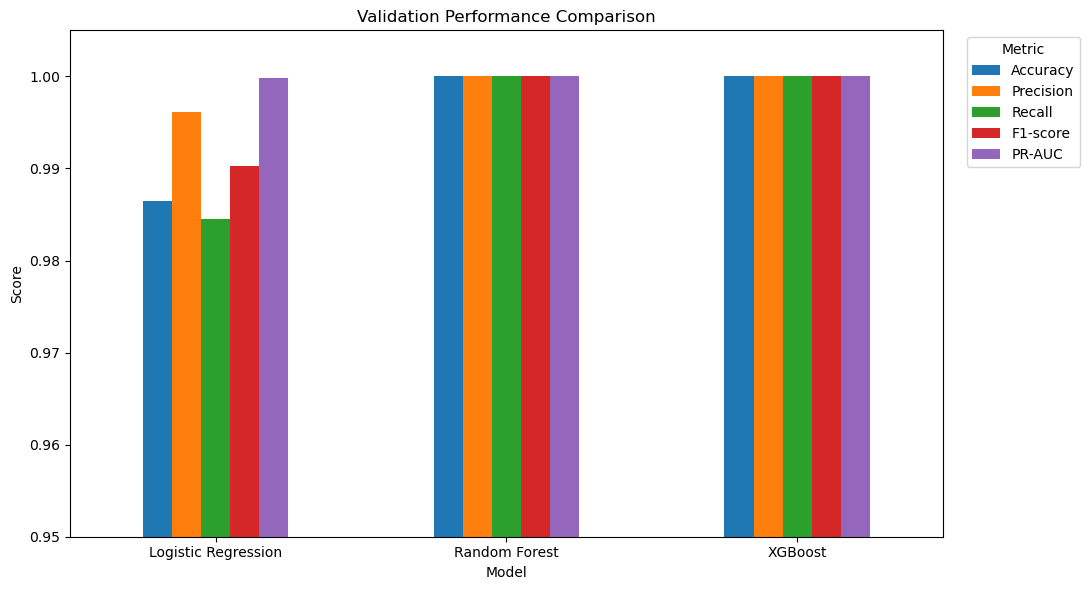

저장 완료: ..\reports\model\model_comparison.png


In [12]:
from pathlib import Path
import matplotlib.pyplot as plt


# 그래프 저장 폴더
model_report_dir = Path("../reports/model")
model_report_dir.mkdir(parents=True, exist_ok=True)


# 비교할 지표
plot_df = model_comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score", "PR-AUC"]
]


ax = plot_df.plot(
    kind="bar",
    figsize=(11, 6),
)

ax.set_title("Validation Performance Comparison")
ax.set_ylabel("Score")
ax.set_ylim(0.95, 1.005)
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=0)

plt.legend(
    title="Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()

save_path = model_report_dir / "model_comparison.png"
plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("저장 완료:", save_path)

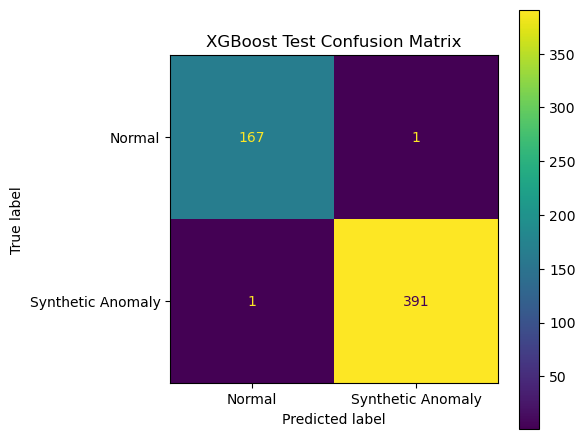

저장 완료: ..\reports\model\xgboost_test_confusion_matrix.png


In [13]:
from sklearn.metrics import ConfusionMatrixDisplay


# =========================================================
# 최종 XGBoost Test Confusion Matrix
# =========================================================

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=[
        "Normal",
        "Synthetic Anomaly",
    ],
    values_format="d",
    ax=ax,
)

ax.set_title("XGBoost Test Confusion Matrix")

plt.tight_layout()

save_path = (
    model_report_dir
    / "xgboost_test_confusion_matrix.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("저장 완료:", save_path)

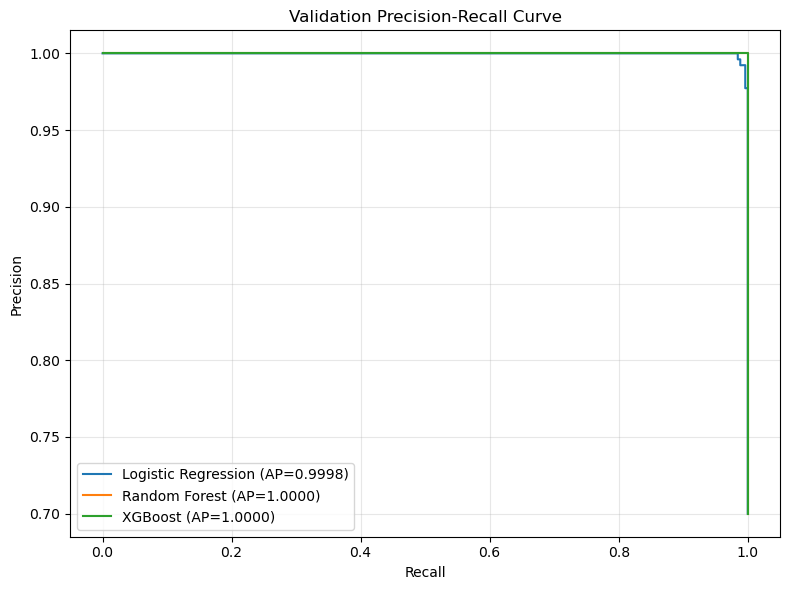

저장 완료: ..\reports\model\validation_pr_curve_comparison.png


In [14]:
from sklearn.metrics import precision_recall_curve


# Logistic Regression
log_precision_curve, log_recall_curve, _ = precision_recall_curve(
    y_val,
    val_prob,
)

# Random Forest
rf_precision_curve, rf_recall_curve, _ = precision_recall_curve(
    y_val,
    rf_val_prob,
)

# XGBoost
xgb_precision_curve, xgb_recall_curve, _ = precision_recall_curve(
    y_val,
    xgb_new_val_prob,
)


plt.figure(figsize=(8, 6))

plt.plot(
    log_recall_curve,
    log_precision_curve,
    label=f"Logistic Regression (AP={pr_auc:.4f})",
)

plt.plot(
    rf_recall_curve,
    rf_precision_curve,
    label=f"Random Forest (AP={rf_pr_auc:.4f})",
)

plt.plot(
    xgb_recall_curve,
    xgb_precision_curve,
    label=f"XGBoost (AP={xgb_new_pr_auc:.4f})",
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

save_path = (
    model_report_dir
    / "validation_pr_curve_comparison.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("저장 완료:", save_path)

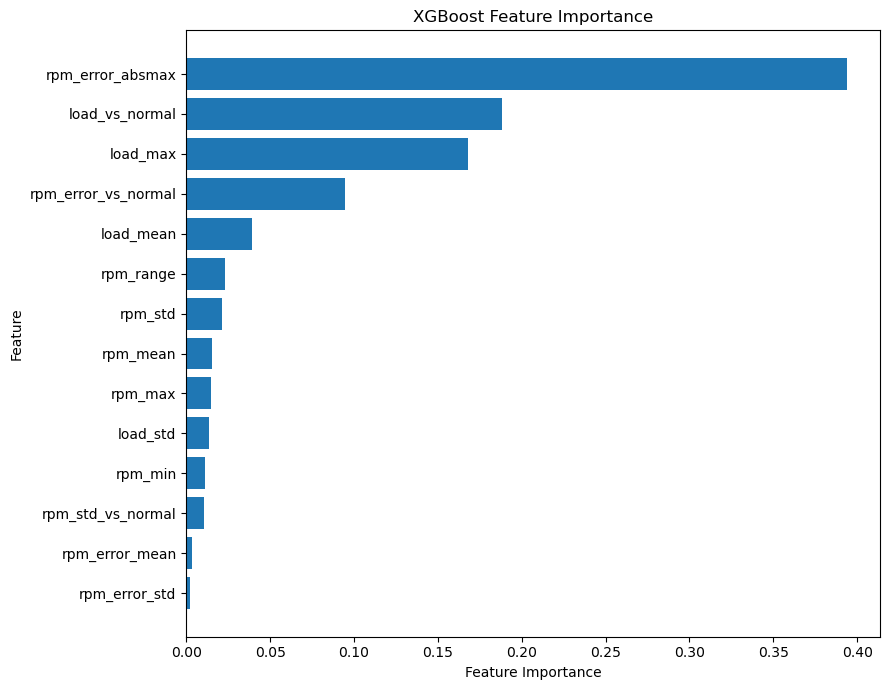

저장 완료: ..\reports\model\xgboost_feature_importance.png


In [15]:
# =========================================================
# XGBoost Feature Importance
# =========================================================

feature_importance = pd.DataFrame({
    "Feature": FEATURE_COLUMNS,
    "Importance": xgb_new_model.feature_importances_,
}).sort_values(
    "Importance",
    ascending=True,
)


plt.figure(figsize=(9, 7))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"],
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance")

plt.tight_layout()

save_path = (
    model_report_dir
    / "xgboost_feature_importance.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("저장 완료:", save_path)

In [16]:
# 모델 비교 결과 저장
model_comparison.to_csv(
    "../reports/model/model_comparison.csv",
    index=False,
    encoding="utf-8-sig",
)


# 최종 XGBoost Test 결과 저장
final_test_result = pd.DataFrame([
    {
        "Model": "XGBoost",
        "Accuracy": test_accuracy,
        "Precision": test_precision,
        "Recall": test_recall,
        "F1-score": test_f1,
        "PR-AUC": test_pr_auc,
        "ROC-AUC": test_roc_auc,
        "Log Loss": test_logloss,
        "Brier Score": test_brier,
    }
])

final_test_result.to_csv(
    "../reports/model/xgboost_test_metrics.csv",
    index=False,
    encoding="utf-8-sig",
)

print("저장 완료")

저장 완료
